# Dense 3DGS render: basic-arch analysis (garden)

DRAM traffic and GlobalBuffer (GLB) occupancy of the FFM-mapper results for the dense 3DGS render
workloads (`3dgs_examples/`, from 3DGSArchSpace.pptx p.2 workload / p.3 arch), swept over GLB size.

| group | workload | what it is |
|---|---|---|
| gaussian project | `workloads/dense/gaussian_project/garden.yaml` | `G2D[v,g] = project(G3D[g], View[v])` alone |
| alpha compute | `workloads/dense/alpha_compute/garden.yaml` | `Alpha[v,g,pu,pv] = f(G2D[v,g])` alone |
| alpha blend | `workloads/dense/alpha_blend/garden.yaml` | `I[v,pu,pv] = blend(Alpha, F2D[v,g])` alone |
| project + alpha compute + alpha blend | the three above, run back to back | unfused: G2D and Alpha go through DRAM |
| render (fusion) | `workloads/dense/render/garden.yaml` | all three Einsums in one cascade; the mapper decides what to fuse |

Arch: `arches/3dgs_render.yaml` (DRAM → GlobalBuffer → {ComputeProjectArray ×256, ComputeAlphaArray ×256,
ComputeBlendArray ×256}).
Mapping results: `3dgs_examples/mappings/dense/<workload>/garden/glb_<bytes>.{yaml,svg}` and
`summary_garden.json`, produced by `3dgs_examples/run_dense_mapping.py` (set `RERUN = True` below to
regenerate them).

GLB occupancy is taken two ways and cross-checked:
1. **mapper** — the per-tensor `usage/memory/GlobalBuffer/<tensor>` reservation the mapper reports
   (`glb_occupancy_bytes` in the summary);
2. **LoopTree walk** — re-derived from the mapping YAML: walk the loop nest, every loop narrows its rank
   to `tile_shape`, and at each `GlobalBuffer` Storage node a tensor's footprint is
   Π(current extent of its projection ranks) × bits_per_value.

In [1]:
import json, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# accelforge repo root (this notebook lives in notebooks/3dgs/dense/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "3dgs_examples").is_dir())
EX = ROOT / "3dgs_examples"
DENSE = EX / "mappings" / "dense"
SCENE = "garden"
RERUN = False  # True: re-run the FFM mapper sweep (~10 s) before analysing

if RERUN:
    subprocess.run([sys.executable, "-u", "3dgs_examples/run_dense_mapping.py", "--scene", SCENE],
                   cwd=ROOT, check=True)

summary = json.loads((DENSE / f"summary_{SCENE}.json").read_text())
GLBS = sorted(r["glb_bytes"] for r in summary["render"])
WORKLOADS = ["gaussian_project", "alpha_compute", "alpha_blend", "render"]
STAGES = ["gaussian_project", "alpha_compute", "alpha_blend"]  # the unfused pipeline, in order
GROUPS = {"gaussian_project": "gaussian project", "alpha_compute": "alpha compute",
          "alpha_blend": "alpha blend", "unfused": "project + alpha compute + alpha blend",
          "render": "render (fusion)"}
TENSORS = ["Alpha", "G2D", "F2D", "I", "G3D", "View"]

def kib(b):
    return f"{b // 1024} KiB" if b < 1 << 20 else f"{b // (1 << 20)} MiB"

row = {wl: {r["glb_bytes"]: r for r in summary[wl]} for wl in WORKLOADS}
print("GLB sizes:", [kib(g) for g in GLBS])

GLB sizes: ['64 KiB', '256 KiB', '1 MiB']


## LoopTree walk: GLB footprint per tensor from the mapping YAMLs

Rank sizes and tensor projections / bits are those of `workloads/dense/*/garden.yaml`
(Nv=185 views, Ng=1,041,334 Gaussians, 622×960 pixels, Alpha 32 b, G3D 352 b, View 1216 b).

In [2]:
RANKS = {"v": 185, "g": 1041334, "pu": 622, "pv": 960}
PROJ = {"G3D": ["g"], "View": ["v"], "G2D": ["v", "g"], "F2D": ["v", "g"], "I": ["v", "pu", "pv"],
        "Alpha": ["v", "g", "pu", "pv"]}
BITS = {"G3D": 352, "View": 1216, "G2D": 192, "F2D": 96, "I": 128, "Alpha": 32}

class _Loader(yaml.SafeLoader):
    pass
_Loader.add_multi_constructor("!", lambda l, tag, node: {"_type": tag, **l.construct_mapping(node, deep=True)})

def glb_footprints(nodes, extent=None, out=None):
    """Bytes each tensor occupies in GlobalBuffer at its Storage node (max over branches)."""
    extent = dict(extent or RANKS)
    out = {} if out is None else out
    for n in nodes:
        t = n["_type"]
        if t in ("Temporal", "Spatial"):
            extent[n["rank_variable"]] = min(extent[n["rank_variable"]], n["tile_shape"])
        elif t == "Storage" and n["component"] == "GlobalBuffer":
            for ten in n["tensors"]:
                size = 1
                for r in PROJ[ten]:
                    size *= extent[r]
                out[ten] = max(out.get(ten, 0), size * BITS[ten] / 8)
        elif t in ("Sequential", "Nested", "Pipeline"):
            if t == "Sequential" or t == "Pipeline":
                for child in n["nodes"]:  # each branch starts from the same extents
                    glb_footprints(child["nodes"] if child["_type"] == "Nested" else [child], extent, out)
            else:
                glb_footprints(n["nodes"], extent, out)
    return out

def glb_phases(nodes, extent=None, held=None):
    """Split a LoopTree into phases that use the GLB at different times.

    Each branch of a Sequential runs after the previous one, so it is its own phase; a phase
    holds every GlobalBuffer Storage on its path from the root. Returns
    [(einsums computed in the phase, {tensor: bytes held})].
    """
    extent = dict(extent or RANKS)
    held = dict(held or {})
    for k, n in enumerate(nodes):
        t = n["_type"]
        if t in ("Temporal", "Spatial"):
            extent[n["rank_variable"]] = min(extent[n["rank_variable"]], n["tile_shape"])
        elif t == "Storage" and n["component"] == "GlobalBuffer":
            for ten in n["tensors"]:
                size = 1
                for r in PROJ[ten]:
                    size *= extent[r]
                held[ten] = size * BITS[ten] / 8
        elif t == "Compute":
            return [([n["einsum"]], held)]
        elif t in ("Sequential", "Pipeline"):
            phases = []
            for child in n["nodes"]:
                sub_nodes = child["nodes"] if child["_type"] == "Nested" else [child]
                phases += glb_phases(sub_nodes, extent, held)
            return _merge_fused(phases)
        elif t == "Nested":
            return glb_phases(n["nodes"] + nodes[k + 1:], extent, held)
    return [([], held)]

def _merge_fused(phases):
    # branches that hold the same GLB tiles are one fused phase (e.g. ComputeAlpha and
    # ComputeBlend under the shared GB[Alpha]); branches with different tiles alternate
    merged = []
    for einsums, held in phases:
        for m in merged:
            if m[1] == held:
                m[0].extend(einsums)
                break
        else:
            merged.append((list(einsums), held))
    return merged

walk, phases = {}, {}
for wl in WORKLOADS:
    for g in GLBS:
        m = yaml.load((DENSE / wl / SCENE / f"glb_{g}.yaml").read_text(), Loader=_Loader)
        walk[wl, g] = glb_footprints(m["mapping"]["nodes"])
        phases[wl, g] = glb_phases(m["mapping"]["nodes"])
        # every tensor's per-phase footprint must agree with the per-tensor max
        per_tensor = {}
        for _, held in phases[wl, g]:
            for ten, b in held.items():
                per_tensor[ten] = max(per_tensor.get(ten, 0), b)
        assert per_tensor == walk[wl, g], (wl, g, per_tensor, walk[wl, g])

check = pd.DataFrame([
    {"workload": wl, "GLB": kib(g), "tensor": t,
     "LoopTree walk (B)": walk[wl, g].get(t, 0.0),
     "mapper (B)": row[wl][g]["glb_occupancy_bytes"].get(t, 0.0)}
    for wl in WORKLOADS for g in GLBS for t in TENSORS
    if walk[wl, g].get(t) or row[wl][g]["glb_occupancy_bytes"].get(t)])
check["match"] = (check["LoopTree walk (B)"] - check["mapper (B)"]).abs() < 1e-6
assert check["match"].all(), check[~check["match"]]
check

,workload,GLB,tensor,LoopTree walk (B),mapper (B),match
0,gaussian_project,64 KiB,G3D,616.0,616.0,True
1,gaussian_project,64 KiB,View,28120.0,28120.0,True
2,gaussian_project,256 KiB,G3D,616.0,616.0,True
3,gaussian_project,256 KiB,View,28120.0,28120.0,True
4,gaussian_project,1 MiB,G3D,616.0,616.0,True
5,gaussian_project,1 MiB,View,28120.0,28120.0,True
6,alpha_compute,64 KiB,G2D,24.0,24.0,True
7,alpha_compute,256 KiB,G2D,24.0,24.0,True
8,alpha_compute,1 MiB,G2D,24.0,24.0,True
9,alpha_blend,64 KiB,F2D,168.0,168.0,True


## Workload: index ranges and tensors

Rank ranges and each tensor's indices / bits per value, rendered from `3dgs_examples/workloads/dense/<workload>/garden.yaml`.

In [3]:
# Index ranges and tensors, read from the workload YAMLs themselves (Jinja defaults rendered)
import jinja2

def load_workload(wl):
    text = (EX / "workloads" / "dense" / wl / f"{SCENE}.yaml").read_text()
    return yaml.safe_load(jinja2.Template(text).render())["workload"]

wls = {wl: load_workload(wl) for wl in WORKLOADS}
space = wls["render"]["iteration_space_shape"]  # superset: all three Einsums
MEANING = {"v": "view (camera)", "g": "Gaussian", "pu": "pixel row", "pv": "pixel column"}

def rank_size(bound):  # "0 <= v < 185" -> 185
    return int(bound.split("<")[-1])

ranks_df = pd.DataFrame([
    {"index": r, "meaning": MEANING.get(r, ""), "range": f"[0, {rank_size(b):,})", "size": rank_size(b)}
    for r, b in space.items()])

tensors = {}
for wl, w in wls.items():
    for e in w["einsums"]:
        for ta in e["tensor_accesses"]:
            t = tensors.setdefault(ta["name"], {"proj": ta["projection"], "bits": ta["bits_per_value"],
                                                "produced": set(), "consumed": set(), "workloads": []})
            (t["produced"] if ta.get("output") else t["consumed"]).add(e["name"])
            if wl not in t["workloads"]:
                t["workloads"].append(wl)

def role(t):
    if t["produced"] and t["consumed"]:
        return "intermediate (in render)"
    return "output" if t["produced"] else "input"

tensor_rows = []
for name, t in tensors.items():
    n = 1
    for r in t["proj"]:
        n *= rank_size(space[r])
    tensor_rows.append({
        "tensor": f"{name}[{', '.join(t['proj'])}]",
        "role": role(t),
        "producer": ", ".join(sorted(t["produced"])) or "-",
        "consumer(s)": ", ".join(sorted(t["consumed"])) or "-",
        "bits / value": t["bits"],
        "elements": n,
        "total size (GB)": n * t["bits"] / 8 / 1e9,
        "workloads": ", ".join(t["workloads"]),
    })
tensors_df = pd.DataFrame(tensor_rows)

# the LoopTree walk above hard-codes these: keep it honest
assert RANKS == {r: rank_size(b) for r, b in space.items()}
assert PROJ == {k: v["proj"] for k, v in tensors.items()}
assert BITS == {k: v["bits"] for k, v in tensors.items()}

display(ranks_df.style.format({"size": "{:,}"}).hide(axis="index"))
display(tensors_df.style.format({"elements": "{:,}", "total size (GB)": "{:,.3f}"}).hide(axis="index"))

index,meaning,range,size
v,view (camera),"[0, 185)",185
g,Gaussian,"[0, 1,041,334)","1,041,334"
pu,pixel row,"[0, 622)",622
pv,pixel column,"[0, 960)",960


tensor,role,producer,consumer(s),bits / value,elements,total size (GB),workloads
G3D[g],input,-,ComputeProject,352,"1,041,334",0.046,"gaussian_project, render"
View[v],input,-,ComputeProject,1216,185,0.000,"gaussian_project, render"
"G2D[v, g]",intermediate (in render),ComputeProject,ComputeAlpha,192,"192,646,790",4.624,"gaussian_project, alpha_compute, render"
"Alpha[v, g, pu, pv]",intermediate (in render),ComputeAlpha,ComputeBlend,32,"115,033,251,244,800","460,133.005","alpha_compute, alpha_blend, render"
"F2D[v, g]",input,-,ComputeBlend,96,"192,646,790",2.312,"alpha_blend, render"
"I[v, pu, pv]",output,ComputeBlend,-,128,"110,467,200",1.767,"alpha_blend, render"


## GLB occupancy breakdown (% of GLB capacity)

Each bar is the buffer's **peak** occupancy. A mapping can use the GLB in phases at different
times: every branch of a `Sequential` in its LoopTree runs after the previous one and reuses the
space (in the fused render, projection's View / G3D tiles, then the alpha → blend nest's I /
Alpha / G2D / F2D tiles). So a bar shows the fullest phase (`peak phase` column), and the table
after it lists every phase. Adding up each tensor's footprint across phases would over-count
(e.g. 112 % for the fused render at 64 KiB).

The **project + alpha compute + alpha blend** group runs the three unfused stages back to back
under the same rule: its bar is the fullest stage. Unfused Alpha streams DRAM ↔ array and is
never placed in the GLB.

In [4]:
def phase_label(wl, einsums):
    return f"{wl}: " + " + ".join(einsums)

# per workload: peak phase of each mapping (the buffer's maximum occupancy)
occ, peak_phase = {}, {}
for wl in WORKLOADS:
    occ[wl], peak_phase[wl] = {}, {}
    for g in GLBS:
        einsums, held = max(phases[wl, g], key=lambda ph: sum(ph[1].values()))
        occ[wl][g], peak_phase[wl][g] = held, phase_label(wl, einsums)
# unfused stages time-share the buffer: its peak is the fullest stage's peak phase
occ["unfused"], peak_phase["unfused"] = {}, {}
for g in GLBS:
    s = max(STAGES, key=lambda s: sum(occ[s][g].values()))
    occ["unfused"][g], peak_phase["unfused"][g] = occ[s][g], peak_phase[s][g]

occ_pct = pd.DataFrame([
    {"group": GROUPS[k], "GLB": kib(g),
     **{t: 100 * occ[k][g].get(t, 0.0) / g for t in TENSORS}}
    for k in GROUPS for g in GLBS])
occ_pct["total"] = occ_pct[TENSORS].sum(axis=1)
occ_pct["unused"] = 100 - occ_pct["total"]
occ_pct["peak phase"] = [peak_phase[k][g] for k in GROUPS for g in GLBS]
display(occ_pct.style.format({c: "{:.2f}" for c in TENSORS + ["total", "unused"]}).hide(axis="index"))

# every phase of every mapping (% of GLB capacity)
phases_df = pd.DataFrame([
    {"workload": wl, "GLB": kib(g), "phase": phase_label(wl, einsums),
     **{t: 100 * held.get(t, 0.0) / g for t in TENSORS}, "total": 100 * sum(held.values()) / g}
    for wl in WORKLOADS for g in GLBS for einsums, held in phases[wl, g]])
assert (phases_df["total"] <= 100 + 1e-9).all(), phases_df[phases_df["total"] > 100]
phases_df.style.format({c: "{:.2f}" for c in TENSORS + ["total"]}).hide(axis="index")

group,GLB,Alpha,G2D,F2D,I,G3D,View,total,unused,peak phase
gaussian project,64 KiB,0.00,0.00,0.00,0.00,0.94,42.91,43.85,56.15,gaussian_project: ComputeProject
gaussian project,256 KiB,0.00,0.00,0.00,0.00,0.23,10.73,10.96,89.04,gaussian_project: ComputeProject
gaussian project,1 MiB,0.00,0.00,0.00,0.00,0.06,2.68,2.74,97.26,gaussian_project: ComputeProject
alpha compute,64 KiB,0.00,0.04,0.00,0.00,0.00,0.00,0.04,99.96,alpha_compute: ComputeAlpha
alpha compute,256 KiB,0.00,0.01,0.00,0.00,0.00,0.00,0.01,99.99,alpha_compute: ComputeAlpha
alpha compute,1 MiB,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,alpha_compute: ComputeAlpha
alpha blend,64 KiB,0.00,0.00,0.26,91.11,0.00,0.00,91.37,8.63,alpha_blend: ComputeBlend
alpha blend,256 KiB,0.00,0.00,0.06,91.11,0.00,0.00,91.18,8.82,alpha_blend: ComputeBlend
alpha blend,1 MiB,0.00,0.00,0.02,91.11,0.00,0.00,91.13,8.87,alpha_blend: ComputeBlend
project + alpha compute + alpha blend,64 KiB,0.00,0.00,0.26,91.11,0.00,0.00,91.37,8.63,alpha_blend: ComputeBlend


workload,GLB,phase,Alpha,G2D,F2D,I,G3D,View,total
gaussian_project,64 KiB,gaussian_project: ComputeProject,0.00,0.00,0.00,0.00,0.94,42.91,43.85
gaussian_project,256 KiB,gaussian_project: ComputeProject,0.00,0.00,0.00,0.00,0.23,10.73,10.96
gaussian_project,1 MiB,gaussian_project: ComputeProject,0.00,0.00,0.00,0.00,0.06,2.68,2.74
alpha_compute,64 KiB,alpha_compute: ComputeAlpha,0.00,0.04,0.00,0.00,0.00,0.00,0.04
alpha_compute,256 KiB,alpha_compute: ComputeAlpha,0.00,0.01,0.00,0.00,0.00,0.00,0.01
alpha_compute,1 MiB,alpha_compute: ComputeAlpha,0.00,0.00,0.00,0.00,0.00,0.00,0.00
alpha_blend,64 KiB,alpha_blend: ComputeBlend,0.00,0.00,0.26,91.11,0.00,0.00,91.37
alpha_blend,256 KiB,alpha_blend: ComputeBlend,0.00,0.00,0.06,91.11,0.00,0.00,91.18
alpha_blend,1 MiB,alpha_blend: ComputeBlend,0.00,0.00,0.02,91.11,0.00,0.00,91.13
render,64 KiB,render: ComputeProject,0.00,0.00,0.00,0.00,0.94,42.91,43.85


## DRAM traffic per run

In [5]:
dram = {wl: [row[wl][g]["dram_bytes"] for g in GLBS] for wl in WORKLOADS}
dram["unfused"] = [sum(dram[s][i] for s in STAGES) for i in range(len(GLBS))]
pd.DataFrame({GROUPS[k]: [d / 1e9 for d in dram[k]] for k in GROUPS},
             index=[kib(g) for g in GLBS]).rename_axis("GLB").style.format("{:,.1f} GB")

,gaussian project,alpha compute,alpha blend,project + alpha compute + alpha blend,render (fusion)
GLB,,,,,
64 KiB,4.7 GB,"460,137.6 GB","460,504.7 GB","920,647.0 GB","2,163.3 GB"
256 KiB,4.7 GB,"460,137.6 GB","460,227.2 GB","920,369.5 GB",283.8 GB
1 MiB,4.7 GB,"460,137.6 GB","460,157.9 GB","920,300.2 GB",75.8 GB


## Plots

In [6]:
SURFACE, INK, INK2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
# categorical slots 1-6: blue, orange, aqua, yellow, magenta, green
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
TCOLOR = dict(zip(TENSORS, SERIES))  # Alpha, G2D, F2D, I keep slots 1-4; G3D, View take 5-6
GCOLOR = dict(zip(GROUPS, SERIES))

def style(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

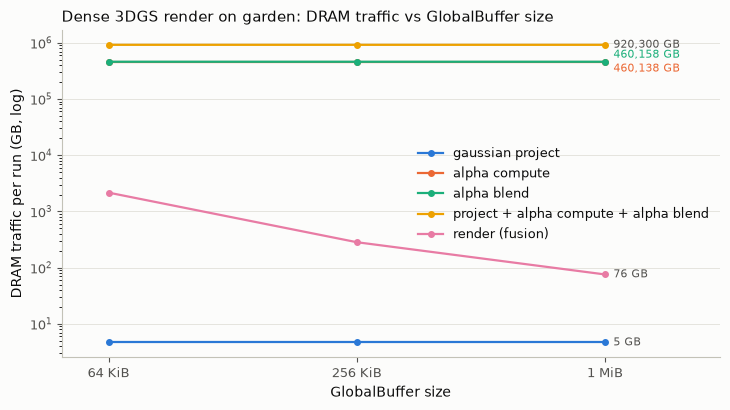

In [7]:
# Plot 1: DRAM traffic vs GLB size
fig, ax = plt.subplots(figsize=(7.4, 4.2), facecolor=SURFACE)
style(ax)
for k, label in GROUPS.items():
    y = [d / 1e9 for d in dram[k]]
    ax.plot(GLBS, y, marker="o", markersize=4, linewidth=1.6, color=GCOLOR[k], label=label)
    nudge = {"alpha_compute": -5, "alpha_blend": 5}.get(k, 0)  # these two overlap within 0.01%
    ax.annotate(f"{y[-1]:,.0f} GB", (GLBS[-1], y[-1]), xytext=(6, nudge), textcoords="offset points",
                va="center", fontsize=8, color=GCOLOR[k] if nudge else INK2)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(GLBS, [kib(g) for g in GLBS])
ax.set_xlim(GLBS[0] / 1.3, GLBS[-1] * 1.9)
ax.set_xlabel("GlobalBuffer size", color=INK)
ax.set_ylabel("DRAM traffic per run (GB, log)", color=INK)
ax.set_title(f"Dense 3DGS render on {SCENE}: DRAM traffic vs GlobalBuffer size",
             color=INK, fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9, labelcolor=INK, loc="center right", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
plt.show()

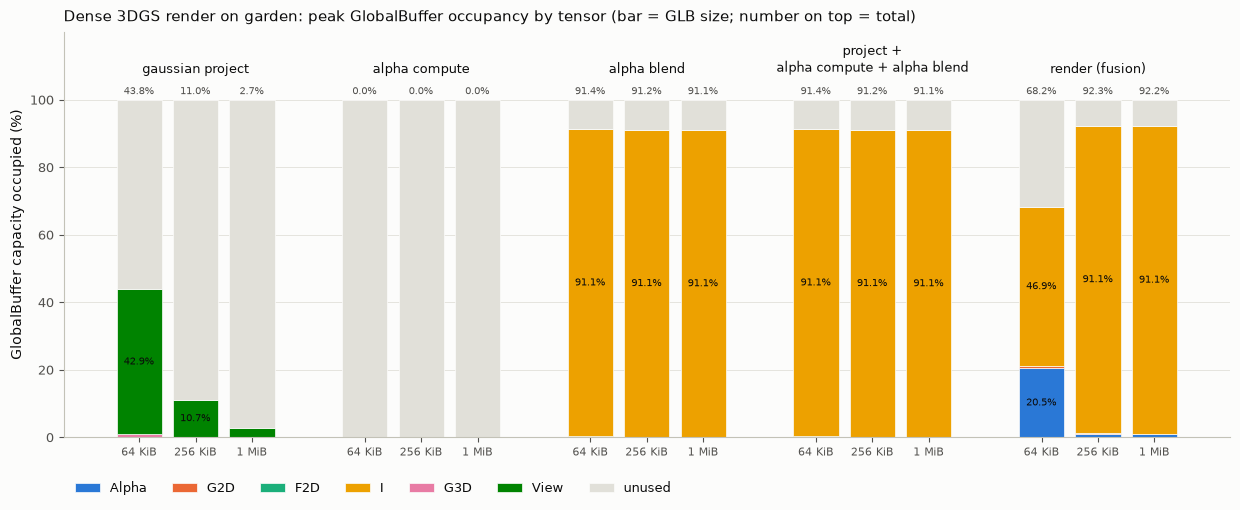

In [8]:
# Plot 2: GLB occupancy breakdown, 5 groups x one stacked bar per GLB size
fig, ax = plt.subplots(figsize=(12.5, 5.2), facecolor=SURFACE)
style(ax)
xs, xlabels = [], []
for gi, k in enumerate(GROUPS):
    for bi, g in enumerate(GLBS):
        x = gi * (len(GLBS) + 1) + bi
        xs.append(x); xlabels.append(kib(g))
        bottom = 0.0
        for t in TENSORS:
            pct = 100 * occ[k][g].get(t, 0.0) / g
            ax.bar(x, pct, 0.8, bottom=bottom, color=TCOLOR[t], edgecolor=SURFACE, linewidth=0.5,
                   label=t if (gi, bi) == (0, 0) else None)
            if pct >= 6:
                ax.text(x, bottom + pct / 2, f"{pct:.1f}%", ha="center", va="center", fontsize=7.5, color=INK)
            bottom += pct
        ax.bar(x, 100 - bottom, 0.8, bottom=bottom, color=GRID, edgecolor=SURFACE, linewidth=0.5,
               label="unused" if (gi, bi) == (0, 0) else None)
        ax.text(x, 101, f"{bottom:.1f}%", ha="center", va="bottom", fontsize=7, color=INK2)
    ax.text(gi * (len(GLBS) + 1) + (len(GLBS) - 1) / 2, 107, GROUPS[k].replace("project + ", "project +\n"),
            ha="center", va="bottom", fontsize=9.5, color=INK)
ax.set_xticks(xs, xlabels, fontsize=8)
ax.set_ylim(0, 120)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("GlobalBuffer capacity occupied (%)", color=INK)
ax.set_title(f"Dense 3DGS render on {SCENE}: peak GlobalBuffer occupancy by tensor (bar = GLB size; "
             "number on top = total)", color=INK, fontsize=11, loc="left", pad=8)
ax.legend(frameon=False, fontsize=9, labelcolor=INK, ncol=7, loc="upper left", bbox_to_anchor=(0, -0.08))
fig.tight_layout()
plt.show()
# exact per-segment percentages (G2D / F2D / G3D are too thin to label on the bars)
occ_pct.pivot_table(index="group", columns="GLB", values=TENSORS, sort=False)[TENSORS] \
    .reindex(columns=[kib(g) for g in GLBS], level=1).style.format("{:.2f}")

## LoopTree viewer

List the mappings to look at in `CONFIGS` as `(WORKLOAD, GLB)` tuples; each one's LoopTree SVG is loaded
from `3dgs_examples/mappings/dense/<workload>/garden/glb_<bytes>.svg` and shown in order
(or call `show_looptree(workload, glb)` directly for a single one).

**gaussian project, GLB 64 KiB** -- `3dgs_examples/mappings/dense/gaussian_project/garden/glb_65536.svg` (YAML: `3dgs_examples/mappings/dense/gaussian_project/garden/glb_65536.yaml`)  
DRAM 4.7 GB, energy 0.5154 J, GLB occupancy: G3D 0.94%, View 42.91%

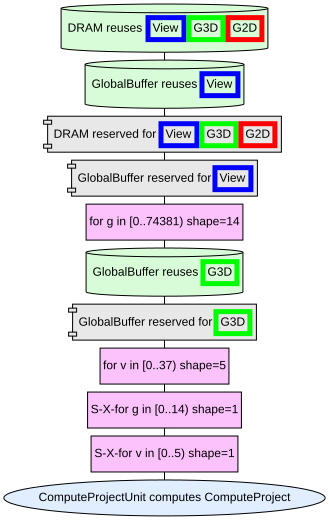

**alpha compute, GLB 64 KiB** -- `3dgs_examples/mappings/dense/alpha_compute/garden/glb_65536.svg` (YAML: `3dgs_examples/mappings/dense/alpha_compute/garden/glb_65536.yaml`)  
DRAM 460,137.6 GB, energy 4.688e+04 J, GLB occupancy: G2D 0.04%

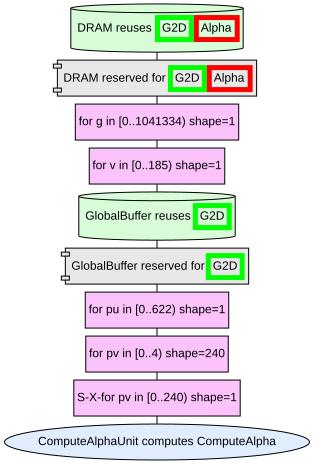

**render (fusion), GLB 1 MiB** -- `3dgs_examples/mappings/dense/render/garden/glb_1048576.svg` (YAML: `3dgs_examples/mappings/dense/render/garden/glb_1048576.yaml`)  
DRAM 75.8 GB, energy 8,243 J, GLB occupancy: G3D 0.06%, View 2.68%, Alpha 1.03%, G2D 0.03%, F2D 0.02%, I 91.11%

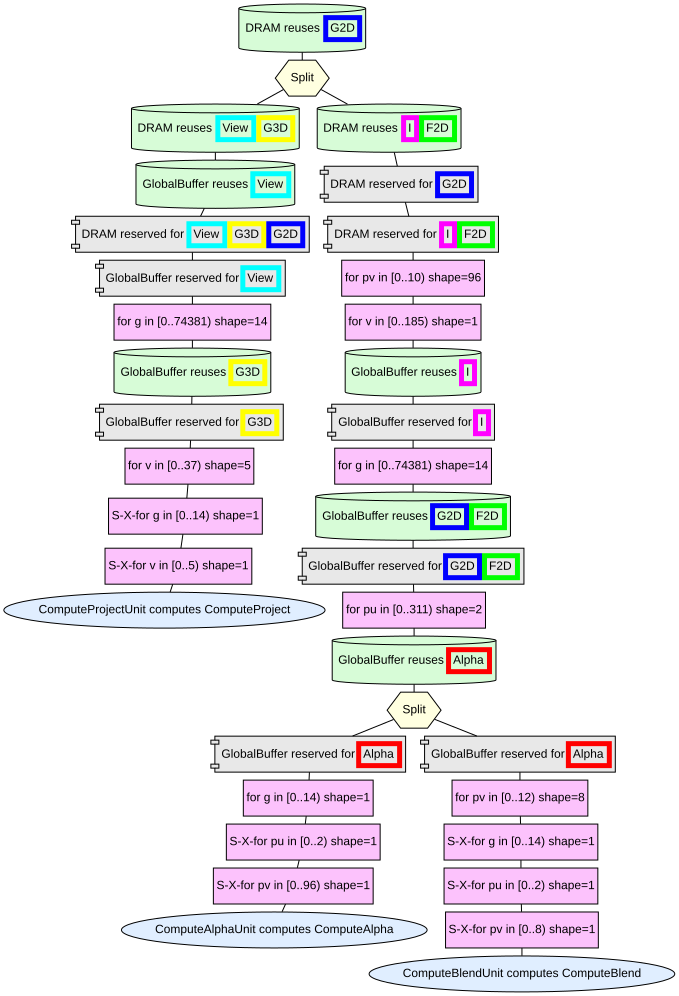

In [9]:
# LoopTree viewer: every (WORKLOAD, GLB) config listed here gets its mapper LoopTree SVG shown below.
# WORKLOAD: "gaussian_project" | "alpha_compute" | "alpha_blend" | "render"
# GLB:      bytes (65536) or "64KiB" / "256KiB" / "1MiB" -- one of the swept sizes in GLBS
CONFIGS = [
    ("gaussian_project", "64KiB"),
    ("alpha_compute", "64KiB"),
    ("render", "1MiB"),
]

from IPython.display import SVG, Markdown

def parse_glb(glb):
    if isinstance(glb, int):
        return glb
    s = glb.replace(" ", "").lower()
    for unit, mult in (("kib", 1 << 10), ("mib", 1 << 20), ("b", 1)):
        if s.endswith(unit):
            return int(float(s[: -len(unit)]) * mult)
    return int(s)

def show_looptree(workload, glb):
    if workload not in WORKLOADS:
        raise ValueError(f"workload must be one of {WORKLOADS}, got {workload!r}")
    g = parse_glb(glb)
    if g not in GLBS:
        raise ValueError(f"GLB {glb!r} = {g} B was not swept; available: {[kib(x) for x in GLBS]}")
    svg = DENSE / workload / SCENE / f"glb_{g}.svg"
    r = row[workload][g]
    occ_str = ", ".join(f"{t} {100 * b / g:.2f}%" for t, b in r["glb_occupancy_bytes"].items()) or "-"
    display(Markdown(
        f"**{GROUPS[workload]}, GLB {kib(g)}** -- `{svg.relative_to(ROOT)}` "
        f"(YAML: `{svg.with_suffix('.yaml').relative_to(ROOT)}`)  \n"
        f"DRAM {r['dram_bytes'] / 1e9:,.1f} GB, energy {r['energy_J']:,.4g} J, GLB occupancy: {occ_str}"))
    display(SVG(filename=str(svg)))

for workload, glb in CONFIGS:
    show_looptree(workload, glb)

## Takeaways

- **Projection is cheap and fully reused on chip.** Alone it moves 4.67 GB of DRAM (G2D written once,
  G3D read once, View read once) at every GLB size. The mapper keeps all 185 `View` cameras in the GLB
  (INRIA format, 152 B each: 28.1 KB, 42.9 % of 64 KiB) and streams a 14-Gaussian G3D tile (616 B).
- **The fused render does not fuse projection.** Its top-level `Sequential` runs ComputeProject over all
  (v, g) first and spills G2D to DRAM; the alpha → blend nest then re-reads G2D once per pixel strip, like a
  primary input (G2D traffic ×312 / ×41 / ×11 its 4.6 GB size at 64 KiB / 256 KiB / 1 MiB = 1 write + the
  311 / 40 / 10 strip re-reads). Keeping G2D on chip would need either recomputing projection per strip or
  holding a whole image of I (622 × 960 × 16 B = 9.6 MB) — larger than any swept GLB. Alpha stays fused.
- **So the fused render uses the GLB in two phases:** projection (View + G3D, 43.8 / 11.0 / 2.7 %), then the
  alpha → blend nest (I + Alpha + G2D + F2D, 68.2 / 92.3 / 92.2 %), which is the peak at every size.
- **I dominates the GLB at the peak (~91 %).** The mapper spends the GLB on a growing pixel strip of I
  (622 × 24 px at 256 KiB, 622 × 96 px at 1 MiB, 16 B/px); the G2D / F2D tiles stay at 14 Gaussians
  (336 B / 168 B), so their share falls as the buffer grows.
- **Fused render at 64 KiB is the exception:** the outer loop splits pixel *rows* (pu/2, 311 trips), so I is
  only 2 × 960 px (30 KB, 46.9 %) next to the Alpha tile (13 KB, 20.5 %).
- **DRAM:** fusion keeps Alpha (460 TB per run) on chip; the fused render falls with GLB size
  (2,163 → 284 → 76 GB) because a larger I strip cuts the G2D / F2D refetch factor (311 → 40 → 10). The unfused
  pipeline stays at ~920,300 GB, dominated by Alpha's write + read.